# Graph Barycenter Exploration - Demo, Adjacency



## Goal

Explore graph barycenters (partial GW / GW) with a stable, reproducible visualization scheme.

Reference notebook: `PGW_Metric_self_edit/graph_matching/tushar_example.ipynb`

Proposed pipeline:
1. Generate a family of similar graphs with small structural variations.
2. Define relation matrices (adjacency / shortest path / heat kernel).
3. Compute (partial) GW barycenter.
4. Visualize barycenter and inputs with a fixed layout scheme.
5. Transfer barycenter colors to input graphs for consistent interpretation.


In [1]:
# Imports (align with tushar_example.ipynb as needed)
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# POT / repo modules
import ot
from lib.gromov import partial_gromov_ver1, gromov_wasserstein, GW_dist, PGW_dist_with_penalty
from lib.gromov_barycenter import *
from lib.opt import *

# Optional: local helper functions can be added below


In [2]:
# 1) Graph family generation (start from hexagon example)

def _base_graph(kind="hex", spacing=1.0):
    if kind == "hex":
        G = nx.cycle_graph(6)
        nx.set_edge_attributes(G, spacing, "weight")
        return G
    if kind == "grid":
        # 2x3 grid -> relabel to integer nodes
        G = nx.grid_2d_graph(3, 3)
        G = nx.convert_node_labels_to_integers(G)
        nx.set_edge_attributes(G, spacing, "weight")
        return G
    if kind == "ladder":
        G = nx.ladder_graph(4)  # 2x4 ladder
        nx.set_edge_attributes(G, spacing, "weight")
        return G
    raise ValueError("kind must be one of: hex, grid, ladder")


def _perturb_graph(G, rng, p_add=0.0, p_remove=0.0, p_leaf=1.0):
    H = G.copy()

    # Optionally remove one existing edge
    if H.number_of_edges() > 0 and rng.random() < p_remove:
        u, v = list(H.edges())[rng.integers(H.number_of_edges())]
        H.remove_edge(u, v)

    # Optionally add an edge between two non-adjacent nodes
    if rng.random() < p_add:
        nodes = list(H.nodes())
        if len(nodes) >= 2:
            for _ in range(10):
                u, v = rng.choice(nodes, size=2, replace=False)
                if not H.has_edge(u, v):
                    H.add_edge(u, v, weight=1.0)
                    break

    # Optionally add a leaf node to a random existing node
    if rng.random() < p_leaf:
        new_node = max(H.nodes()) + 1
        attach = rng.choice(list(H.nodes()))
        H.add_edge(int(attach), int(new_node), weight=1.0)

    return H


def make_graph_family(kind="hex", n_graphs=3, seed=7):
    rng = np.random.default_rng(seed)
    base = _base_graph(kind=kind)
    graphs = [base]
    for _ in range(n_graphs - 1):
        graphs.append(_perturb_graph(base, rng))
    return graphs


# Example: create three similar graphs
Gs = make_graph_family(kind="grid", n_graphs=3, seed=31)
# Try another family by switching kind to "grid" or "ladder".



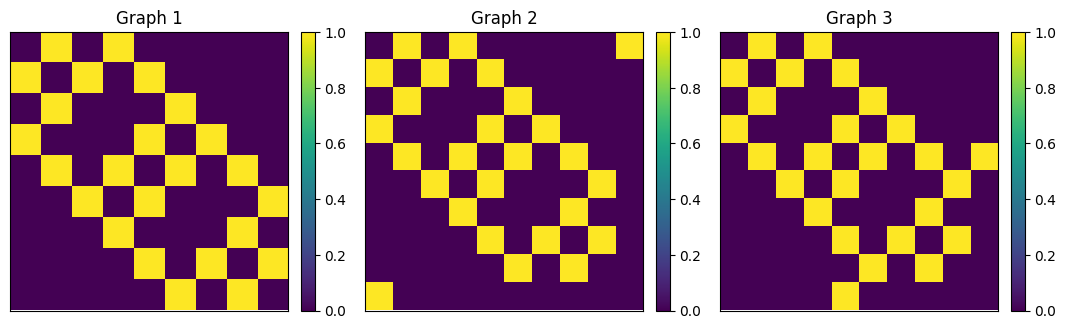

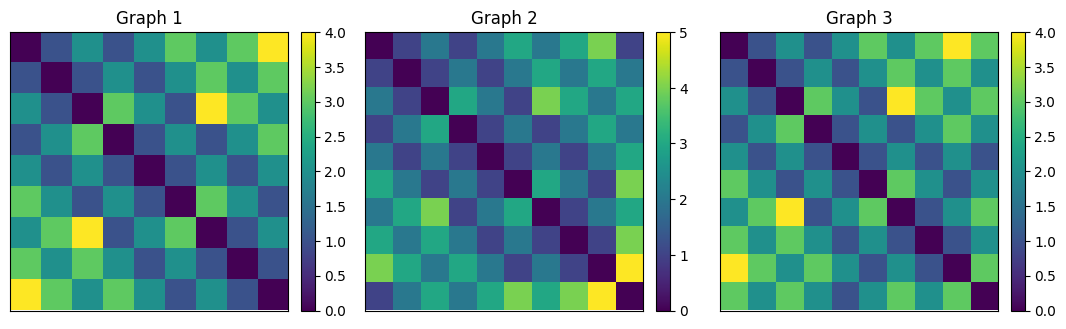

In [3]:
# 1.5) Pairwise relation matrices (quick check)

def _relation_matrix_basic(G, kind="adjacency"):
    kind = kind.lower()
    if kind == "adjacency":
        A = nx.to_numpy_array(G, dtype=float, weight="weight")
        A = (A != 0).astype(float)
        return A
    if kind == "shortestpath":
        return nx.floyd_warshall_numpy(G, weight=None)
    raise ValueError("kind must be 'adjacency' or 'shortestpath' for this quick check")


def show_relation_matrices(graphs, kind="adjacency", cmap="viridis"):
    n = len(graphs)
    fig, axes = plt.subplots(1, n, figsize=(3.6 * n, 3.2), squeeze=False)
    for i, G in enumerate(graphs):
        M = _relation_matrix_basic(G, kind=kind)
        ax = axes[0, i]
        im = ax.imshow(M, cmap=cmap)
        ax.set_title(f"Graph {i+1}")
        ax.set_xticks([])
        ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

# Example:
show_relation_matrices(Gs, kind="adjacency")
show_relation_matrices(Gs, kind="shortestpath")


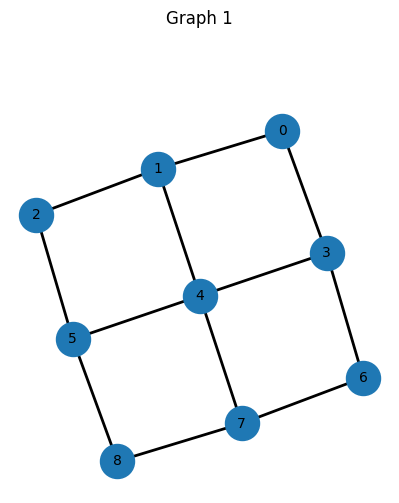

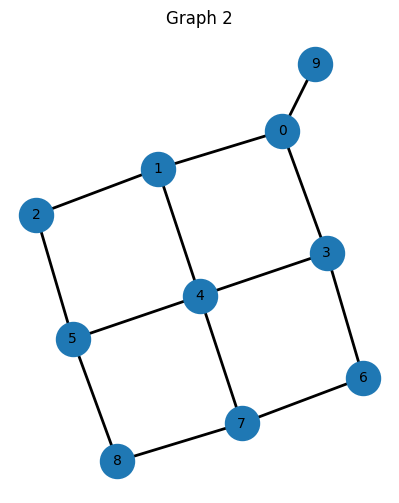

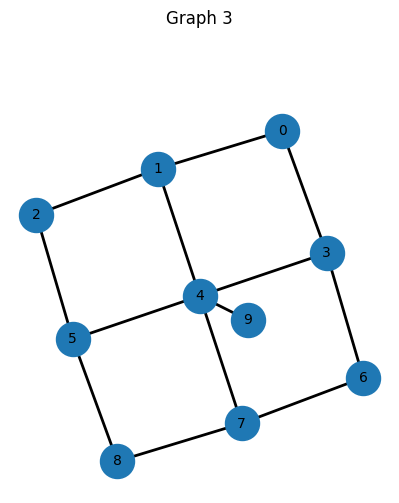

In [4]:
# 2) Stable visualization scheme

def _swap_positions(pos, swaps):
    if not swaps:
        return pos
    pos = {k: np.array(v, dtype=float) for k, v in pos.items()}
    for a, b in swaps:
        if a in pos and b in pos:
            pos[a], pos[b] = pos[b].copy(), pos[a].copy()
    return pos


def _unified_layout(
    graphs,
    base_index=0,
    seed=7,
    k=None,
    iterations=300,
    jitter=0.05,
    weight_attr="weight",
    swaps=None,
):
    """
    Basic directed force layout (spring) with optional node swaps on the base.
    For other graphs, shared nodes are fixed to base positions.
    """
    if len(graphs) == 0:
        return []

    base = graphs[base_index]
    n_base = max(1, base.number_of_nodes())
    kk = k if k is not None else 1.0 / np.sqrt(n_base)

    base_pos = nx.spring_layout(base, seed=seed, k=kk, iterations=iterations, weight=weight_attr)
    if swaps:
        base_pos = _swap_positions(base_pos, swaps)
        fixed = [n for pair in swaps for n in pair if n in base_pos]
        if fixed:
            base_pos = nx.spring_layout(
                base,
                pos=base_pos,
                fixed=fixed,
                seed=seed,
                k=kk,
                iterations=iterations,
                weight=weight_attr,
            )

    pos_list = []
    rng = np.random.default_rng(seed)
    for i, G in enumerate(graphs):
        if i == base_index:
            pos_list.append(base_pos)
            continue

        shared = [n for n in G.nodes() if n in base_pos]
        fixed = shared if shared else None
        init_pos = {n: base_pos[n] for n in shared}

        for n in G.nodes():
            if n in init_pos:
                continue
            neighbors = list(G.neighbors(n))
            anchor = next((u for u in neighbors if u in base_pos), None)
            if anchor is not None:
                init_pos[n] = base_pos[anchor] + jitter * rng.normal(size=2)

        n = max(1, G.number_of_nodes())
        kk_g = k if k is not None else 1.0 / np.sqrt(n)
        pos = nx.spring_layout(
            G,
            pos=init_pos if init_pos else None,
            fixed=fixed,
            seed=seed,
            k=kk_g,
            iterations=iterations,
            weight=weight_attr,
        )
        pos_list.append(pos)

    return pos_list


def draw_graphs_unified(
    graphs,
    base_index=0,
    seed=7,
    k=None,
    iterations=300,
    figsize=(4.8, 4.8),
    weight_attr="weight",
    swaps=None,
):
    """Draw each graph with a unified layout and shared axes limits."""
    pos_list = _unified_layout(
        graphs,
        base_index=base_index,
        seed=seed,
        k=k,
        iterations=iterations,
        weight_attr=weight_attr,
        swaps=swaps,
    )

    # compute global bbox over all positions
    xs, ys = [], []
    for pos in pos_list:
        for x, y in pos.values():
            xs.append(x)
            ys.append(y)
    if not xs:
        xs, ys = [0.0], [0.0]
    xmin, xmax = min(xs), max(xs)
    ymin, ymax = min(ys), max(ys)
    wx, wy = xmax - xmin, ymax - ymin
    if wx == 0:
        wx = 1e-6
    if wy == 0:
        wy = 1e-6
    pad = 0.08
    xmin -= pad * wx
    xmax += pad * wx
    ymin -= pad * wy
    ymax += pad * wy

    for i, (G, pos) in enumerate(zip(graphs, pos_list), start=1):
        fig = plt.figure(figsize=figsize)
        ax = fig.add_axes([0.02, 0.02, 0.96, 0.96])
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.set_axis_off()

        nx.draw_networkx(G, pos, ax=ax, node_size=600, font_size=10, width=2.0)
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.set_title(f"Graph {i}", pad=6)

    plt.show()


# Example visualization
# Swap nodes on the base graph if needed, then re-run force layout.
# Example: swaps=[(0, 2)] for ladder-like symmetry.
draw_graphs_unified(Gs, base_index=0, seed=31, swaps=None)



In [5]:
# 3) Relation matrices

def relation_matrix(
    G,
    kind="adjacency",
    *,
    nodelist=None,
    laplacian_base="adjacency",  # "adjacency" | "shortestpath"
    laplacian_normalization="none",  # "none" | "sym" | "rw"
    tau=1.0,
    sp_weighted=False,
    sp_affinity="exp",  # "exp" | "inverse"
    sp_sigma=None,
):
    """
    Build relation matrices for graphs.

    kind:
      - "adjacency": adjacency matrix (0/1 or weights)
      - "shortestpath": shortest-path distances
      - "laplacian": heat kernel exp(-tau * L) where L is from adjacency or
        from a shortest-path derived affinity matrix.

    laplacian_base:
      - "adjacency": Laplacian from adjacency weights
      - "shortestpath": Laplacian from affinity built off shortest-path distances

    sp_affinity:
      - "exp": A_ij = exp(-D_ij / sigma)
      - "inverse": A_ij = 1 / (D_ij + eps)
    """
    if nodelist is None:
        nodelist = list(G.nodes())

    kind = kind.lower()
    laplacian_base = laplacian_base.lower()
    laplacian_normalization = laplacian_normalization.lower()
    sp_affinity = sp_affinity.lower()

    if kind == "adjacency":
        A = nx.to_numpy_array(G, nodelist=nodelist, dtype=float, weight="weight")
        A = (A != 0).astype(float)
        return A, nodelist

    if kind == "shortestpath":
        D = nx.floyd_warshall_numpy(G, nodelist=nodelist, weight="weight" if sp_weighted else None)
        return D, nodelist

    if kind != "laplacian":
        raise ValueError("kind must be one of: adjacency, shortestpath, laplacian")

    # --- Laplacian heat kernel ---
    if laplacian_base == "adjacency":
        A = nx.to_numpy_array(G, nodelist=nodelist, dtype=float, weight="weight")
    elif laplacian_base == "shortestpath":
        D = nx.floyd_warshall_numpy(G, nodelist=nodelist, weight="weight" if sp_weighted else None)
        # Convert distances to affinities
        finite = np.isfinite(D) & (D > 0)
        if sp_affinity == "exp":
            if sp_sigma is None:
                # median of finite, non-zero distances
                sp_sigma = np.median(D[finite]) if np.any(finite) else 1.0
            A = np.zeros_like(D, dtype=float)
            A[finite] = np.exp(-D[finite] / max(sp_sigma, 1e-12))
        elif sp_affinity == "inverse":
            A = np.zeros_like(D, dtype=float)
            A[finite] = 1.0 / (D[finite] + 1e-12)
        else:
            raise ValueError("sp_affinity must be 'exp' or 'inverse'")
        np.fill_diagonal(A, 0.0)
    else:
        raise ValueError("laplacian_base must be 'adjacency' or 'shortestpath'")

    # build Laplacian
    if laplacian_normalization == "none":
        deg = np.sum(A, axis=1)
        L = np.diag(deg) - A
    elif laplacian_normalization == "sym":
        deg = np.sum(A, axis=1)
        with np.errstate(divide="ignore"):
            inv_sqrt = np.where(deg > 0, 1.0 / np.sqrt(deg), 0.0)
        Dm = np.diag(inv_sqrt)
        L = np.eye(A.shape[0]) - Dm @ A @ Dm
    elif laplacian_normalization == "rw":
        deg = np.sum(A, axis=1)
        with np.errstate(divide="ignore"):
            inv = np.where(deg > 0, 1.0 / deg, 0.0)
        Dm = np.diag(inv)
        L = np.eye(A.shape[0]) - Dm @ A
    else:
        raise ValueError("laplacian_normalization must be 'none', 'sym', or 'rw'")

    # heat kernel exp(-tau * L)
    try:
        import scipy.linalg as sla
        H = sla.expm((-tau) * L)
    except Exception:
        w, V = np.linalg.eigh(L)
        H = (V * np.exp(-tau * w)) @ V.T

    return H, nodelist


# Example usage:
# A, _ = relation_matrix(Gs[0], kind="adjacency")
# D, _ = relation_matrix(Gs[0], kind="shortestpath")
# H_adj, _ = relation_matrix(Gs[0], kind="laplacian", laplacian_base="adjacency", tau=1.0)
# H_sp, _ = relation_matrix(Gs[0], kind="laplacian", laplacian_base="shortestpath", tau=1.0)



In [6]:
# 4) Barycenter computation (demo for Gs[idx_0] and Gs[idx_1])
import importlib
import lib.gromov as gromov
import lib.gromov_barycenter as gromov_barycenter
importlib.reload(gromov)
importlib.reload(gromov_barycenter)

# Re-import the functions you use in the notebook
from lib.gromov import partial_gromov_ver1, gromov_wasserstein, GW_dist, PGW_dist_with_penalty
from lib.gromov_barycenter import *

# --- Relation matrix selection ---
relation_kind = "adjacency"           # "adjacency" | "shortestpath" | "laplacian"
laplacian_base = "adjacency"          # "adjacency" | "shortestpath"
laplacian_normalization = "none"      # "none" | "sym" | "rw"
tau = 1.0                              # heat kernel time for laplacian
sp_weighted = False                    # use weighted edges for shortest paths
sp_affinity = "exp"                   # "exp" | "inverse" (if laplacian_base="shortestpath")
sp_sigma = None                        # scale for exp affinity; None -> median distance

# --- Barycenter solver selection ---
use_partial = True                     # True: partial GW barycenter; False: GW barycenter
idx_list = [0, 1, 2]
N_center = max([Gs[idx].number_of_nodes() for idx in idx_list]) + 1 # target barycenter size
lambdas = np.ones(len(idx_list), dtype=float) / len(idx_list)   # weights for each input graph
max_iter = 200                         # max iterations for barycenter solver
bary_tol = 1e-6                        # convergence tolerance on barycenter updates
random_state = 0                       # reproducibility for initialization
lambda_penalty = 0.20                  # partial GW penalty (None -> default per-graph max(C))

print(N_center)

# --- Coupling restarts during barycenter optimization ---
gw_restarts = 100                      # number of restarts per GW coupling (per graph, per iteration)
gw_seed_start = 0                      # seed offset for coupling restarts

# Build relation matrices
Cs = []
nodes_list = []
for idx in idx_list:
    C_idx, nodes_idx = relation_matrix(
        Gs[idx],
        kind=relation_kind,
        laplacian_base=laplacian_base,
        laplacian_normalization=laplacian_normalization,
        tau=tau,
        sp_weighted=sp_weighted,
        sp_affinity=sp_affinity,
        sp_sigma=sp_sigma,
    )
    Cs.append(C_idx)
    nodes_list.append(nodes_idx)

# Distributions on input graphs (uniform over nodes)
# Note: No guarantee that the sum of each p is equal
# ps = [np.ones(C0.shape[0]) / C0.shape[0], np.ones(C1.shape[0]) / C1.shape[0]]
ps = [np.ones(C.shape[0]) for C in Cs]

# Distribution on barycenter nodes
# p = np.ones(N_center) / N_center
p = np.ones(N_center)

if use_partial:
    # Partial GW barycenter (penalizes mass removal)
    Lambda_list = None if lambda_penalty is None else [lambda_penalty] * len(idx_list)

    # --- Multi-start init without extra total iterations ---
    init_restarts = 5   # number of initializations to try
    init_iters = max_iter // (init_restarts + 1)  # keep total iters ~ max_iter
    remaining_iters = max_iter - init_restarts * init_iters
    
    print(init_restarts, init_iters)

    def _pgw_total_cost(C_tmp, log_tmp):
        total = 0.0
        for s in range(len(Cs)):
            dist, penalty = PGW_dist_with_penalty(C_tmp, Cs[s], log_tmp["T"][s], p, ps[s], Lambda_list[s])
            total += lambdas[s] * (dist + penalty)
        return float(total)

    if init_restarts <= 1 or init_iters <= 0:
        C_center, log = pgw_barycenters(
            N=N_center,
            Cs=Cs,
            ps=ps,
            p=p,
            Lambda_list=Lambda_list,
            lambdas=lambdas,
            max_iter=max_iter,
            tol=bary_tol,
            log=True,
            random_state=random_state,
            gw_restarts=gw_restarts,
            gw_seed_start=gw_seed_start,
            debug=False,
        )
    else:
        best = None
        for r in range(init_restarts):
            seed = random_state + r
            C_tmp, log_tmp = pgw_barycenters(
                N=N_center,
                Cs=Cs,
                ps=ps,
                p=p,
                Lambda_list=Lambda_list,
                lambdas=lambdas,
                max_iter=init_iters,
                tol=bary_tol,
                log=True,
                random_state=seed,
                gw_restarts=gw_restarts,
                gw_seed_start=gw_seed_start,
                debug=False,
            )
            cost = _pgw_total_cost(C_tmp, log_tmp)
            if (best is None) or (cost < best["cost"]):
                best = {"seed": seed, "cost": cost, "C": C_tmp}
            print(f'seed at {seed} is done')
        print("best:", best)
        if np.any(np.isnan(best["C"])):
            print("NaN values found in C! No implementation to replace these values yet. "
                    "We discard the best C and only reuse the best initial states!")
            best["C"] = None

        # continue from best initialization
        C_center, log = pgw_barycenters(
            N=N_center,
            Cs=Cs,
            ps=ps,
            p=p,
            Lambda_list=Lambda_list,
            lambdas=lambdas,
            max_iter=max(1, remaining_iters),
            tol=bary_tol,
            log=True,
            init_C=best["C"],
            random_state=best["seed"],
            gw_restarts=gw_restarts,
            gw_seed_start=gw_seed_start,
            debug=False,
        )
else:
    # Standard GW barycenter
    C_center, log = gromov_barycenters(
        N=N_center,
        Cs=Cs,
        ps=ps,
        p=p,
        lambdas=lambdas,
        max_iter=max_iter,
        tol=bary_tol,
        log=True,
        random_state=random_state,
    )

print("Barycenter matrix shape:", C_center.shape)


11
5 33


c:\Users\mingz\anaconda3\envs\pOTbarycenter\Lib\site-packages\ot\bregman\_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(
c:\Users\mingz\anaconda3\envs\pOTbarycenter\Lib\site-packages\ot\bregman\_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


seed at 0 is done
seed at 1 is done
seed at 2 is done
seed at 3 is done
seed at 4 is done
best: {'seed': 0, 'cost': 5.466666666666664, 'C': array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 6.33333333e-16,
        1.00000000e+00, 0.00000000e+00, 6.33333333e-16, 0.00000000e+00,
        0.00000000e+00, 1.00000000e+00, 1.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 6.33333333e-16,
        0.00000000e+00, 0.00000000e+00, 6.33333333e-16, 1.00000000e+00,
        0.00000000e+00, 1.00000000e+00, 1.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 6.33333333e-16,
        1.00000000e+00, 1.00000000e+00, 6.33333333e-16, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 1.00000000e+00],
       [6.33333333e-16, 6.33333333e-16, 6.33333333e-16, 5.56296296e-31,
        5.22222222e-16, 4.22222222e-16, 1.00000000e-01, 4.22222222e-16,
        6.33333333e-16, 4.22222222e-16, 1.00000000e+00],
       [1.00000000e+00, 0.00000000e+00, 1.00000000e+00, 

In [7]:
import importlib
import lib.gromov as gromov
import lib.gromov_barycenter as gromov_barycenter
importlib.reload(gromov)
importlib.reload(gromov_barycenter)

# Re-import the functions you use in the notebook
from lib.gromov import partial_gromov_ver1, gromov_wasserstein, GW_dist, PGW_dist_with_penalty
from lib.gromov_barycenter import *

C0 = np.asarray([[0, 1, 0, 1, 0, 0, 0, 0, 0],
      [1, 0, 1, 0, 1, 0, 0, 0, 0],
      [0, 1, 0, 0, 0, 1, 0, 0, 0],
      [1, 0, 0, 0, 1, 0, 1, 0, 0],
      [0, 1, 0, 1, 0, 1, 0 ,1, 0],
      [0, 0, 1, 0, 1, 0, 0, 0, 1],
      [0, 0, 0, 1, 0, 0, 0, 1, 0],
      [0, 0, 0, 0, 1, 0, 1, 0, 1],
      [0, 0, 0, 0, 0, 1, 0, 1, 0]], dtype=float)

p0 = np.ones((9, ))

CC = np.asarray([[0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1],
      [0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1],
      [0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1],
      [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
      [1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0],
      [0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0],
      [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
      [0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0],
      [0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1],
      [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
      [1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0]], dtype=float)

pC = np.ones((11, ))

T_best, best_cost = None, None
T_best_dist, best_dist = None, None
for r in range(gw_restarts):
    seed = gw_seed_start + r
    T = partial_gromov_ver1(
        CC, C0, pC, p0, lambda_penalty, G0=None,
        numItermax_gw=max_iter, tol=1e-5, log=False, verbose=False,
        seed=seed)
    # T = np.asarray(
    #     [[0, 0, 0, 1, 0, 0, 0, 0, 0],
    #      [0, 1, 0, 0, 0, 0, 0, 0, 0],
    #      [0, 0, 0, 0, 0, 0, 0, 1, 0],
    #      [0, 0, 0, 0, 0, 0, 0, 0, 0],
    #      [0, 0, 0, 0, 0, 0, 1, 0, 0],
    #      [0, 0, 0, 0, 0, 0, 0, 0, 1],
    #      [0, 0, 0, 0, 0, 0, 0, 0, 0],
    #      [0, 0, 1, 0, 0, 0, 0, 0, 0],
    #      [0, 0, 0, 0, 0, 1, 0, 0, 0],
    #      [1, 0, 0, 0, 0, 0, 0, 0, 0],
    #      [0, 0, 0, 0, 1, 0, 0, 0, 0],]
    # )
    dist, penalty = PGW_dist_with_penalty(CC, C0, T, pC, p0, lambda_penalty)
    print(T, dist, penalty)
    cost = dist + penalty
    if (best_cost is None) or (cost < best_cost):
        best_cost = cost
        T_best = T
    if (best_dist is None) or (dist < best_dist):
        best_dist = dist
        T_best_dist = T

# print("Best Cost:", best_cost, T_best)
# print("Best Dist:", best_dist, T_best_dist)

[[2.24138133e-07 5.87156506e-17 1.35743136e-10 8.75429819e-12
  1.77636093e-04 3.78135562e-13 4.88011844e-05 1.84171440e-37
  6.82974704e-27]
 [2.16041834e-16 1.76546834e-36 1.38928779e-23 5.47448804e-29
  1.78847210e-42 9.99598607e-01 5.13608405e-06 8.28639860e-16
  2.12585750e-37]
 [8.58943267e-31 3.87779894e-37 2.25550343e-40 2.77256179e-36
  1.41426473e-19 3.45887295e-04 1.25807875e-04 5.58102760e-40
  1.00853686e-04]
 [3.45887295e-04 5.01085683e-01 1.61159289e-07 1.05217734e-04
  8.50118290e-25 5.29067536e-10 8.15125806e-16 4.98412681e-01
  5.85562989e-17]
 [2.60468737e-13 7.07101979e-16 1.37243601e-28 9.99722969e-01
  7.06231891e-05 2.89712706e-07 1.61590305e-19 1.55748658e-04
  3.48327467e-17]
 [4.98801472e-01 4.83267543e-10 2.33469465e-03 7.92995697e-17
  6.99552063e-17 7.19604875e-25 4.98291399e-01 3.45887295e-04
  1.76177110e-04]
 [4.98405513e-01 5.84803950e-05 7.75933929e-25 3.54358625e-11
  2.19061500e-18 9.05240747e-08 5.01485546e-01 1.39463442e-15
  1.33436574e-25]
 [2.44

In [8]:
# 4.1) Inspect barycenter relation matrix
# Note: C_center is the relation matrix in the same type as `relation_kind`.
print("relation_kind:", relation_kind)
print("C_center shape:", C_center.shape)
print(C_center)
print(np.sum(C_center, axis=0))
print(np.sum(C_center, axis=1))

if relation_kind == "adjacency":
    C_center[np.isnan(C_center)] = 0
    print("update adjacency to replace NaN with 0 (if any)...")
    print("Updated adjacency:", C_center)

relation_kind: adjacency
C_center shape: (11, 11)
[[0.00000000e+00 0.00000000e+00 0.00000000e+00 6.33333333e-16
  1.00000000e+00 0.00000000e+00 6.33333333e-16 0.00000000e+00
  0.00000000e+00 1.00000000e+00 1.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 6.33333333e-16
  0.00000000e+00 0.00000000e+00 6.33333333e-16 1.00000000e+00
  0.00000000e+00 1.00000000e+00 1.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 6.33333333e-16
  1.00000000e+00 1.00000000e+00 6.33333333e-16 0.00000000e+00
  0.00000000e+00 0.00000000e+00 1.00000000e+00]
 [6.33333333e-16 6.33333333e-16 6.33333333e-16 5.56296296e-31
  5.22222222e-16 4.22222222e-16 1.00000000e-01 4.22222222e-16
  6.33333333e-16 4.22222222e-16 1.00000000e+00]
 [1.00000000e+00 0.00000000e+00 1.00000000e+00 5.22222222e-16
  0.00000000e+00 0.00000000e+00 1.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00 4.22222222e-16
  0.00000000e+00 0.00000000e

In [9]:
# 4.2.1) Diagnose zero-mass rows during barycenter iterations
# Requires pgw_barycenters(debug=True). Prints the last iteration stats.

if "debug" not in log:
    print("No debug info found. Set debug=True in pgw_barycenters.")
elif not log["debug"]:
    print("Debug log is empty.")
else:
    last = log["debug"][-1]
    print("Iteration:", last["iter"])
    print("Rows with zero mass in at least one graph:", last["zero_any"].tolist())
    print("Rows with zero mass in ALL graphs:", last["zero_all"].tolist())
    print("Row-sum table (S x N_center):\n", last["row_sums"])
    zp = last.get("zero_ppt")
    if zp is not None:
        print("Zero entries in ppt (denominator) count:", len(zp[0]))
        # show up to 20 indices
        pairs = list(zip(zp[0], zp[1]))
        print("Zero-ppt indices (sample):", pairs[:20])
    else:
        print("zp:", zp)


No debug info found. Set debug=True in pgw_barycenters.


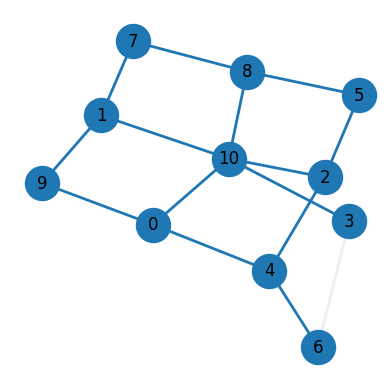

0.10000000000000009 0.10000000000000009
0.9999999999999989 0.9999999999999989
0.9999999999999983 0.9999999999999983
1.0 1.0


In [14]:
# 4.2) Draw barycenter graph (adjacency weights -> edge alpha)
# Assumes C_center is an adjacency-like matrix (0..1).

def _graph_from_adjacency_threshold(A, tol=0.0):
    A = np.asarray(A, dtype=float)
    A = np.nan_to_num(A, nan=0.0)
    np.fill_diagonal(A, 0.0)
    G = nx.Graph()
    n = A.shape[0]
    G.add_nodes_from(range(n))
    for i in range(n):
        for j in range(i + 1, n):
            w = A[i, j]
            if w > tol:
                G.add_edge(i, j, weight=float(w))
    return G


def draw_graph_with_alpha(G, pos=None, seed=7, node_size=600, width=2.0, base_color="#1f77b4"):
    if pos is None:
        pos = nx.spring_layout(G, seed=seed)
    ws = [d.get("weight", 0.0) for _, _, d in G.edges(data=True)]
    if ws:
        wmin, wmax = min(ws), max(ws)
        if wmax <= wmin:
            alphas = [1.0] * len(ws)
        else:
            alphas = [(w - wmin) / (wmax - wmin) for w in ws]
    else:
        alphas = []

    fig, ax = plt.subplots(figsize=(4.8, 4.8))
    nx.draw_networkx_nodes(G, pos, node_size=node_size, ax=ax)
    for (e, a) in zip(G.edges(), alphas):
        nx.draw_networkx_edges(G, pos, edgelist=[e], width=width, edge_color=base_color, alpha=a, ax=ax)
    nx.draw_networkx_labels(G, pos, ax=ax)
    ax.set_axis_off()
    plt.show()


# Build and draw barycenter graph from adjacency-like C_center
if relation_kind != "adjacency":
    print("Warning: relation_kind is not 'adjacency'. This draw assumes adjacency weights.")


G_center = _graph_from_adjacency_threshold(C_center, tol=0.0)
# reuse base layout if desired: pos = _unified_layout([G_center], seed=31)[0]
# draw_graph_with_alpha(G_center, pos=pos)
draw_graph_with_alpha(G_center)

print(C_center[3, 6], C_center[6, 3])
print(C_center[3, 10], C_center[10, 3])
print(C_center[4, 6], C_center[6, 4])
print(C_center[1, 7], C_center[7, 1])


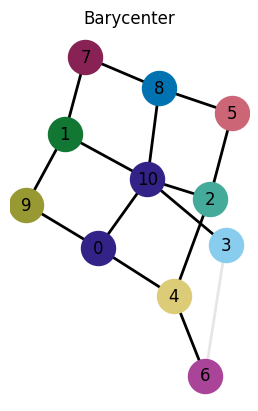

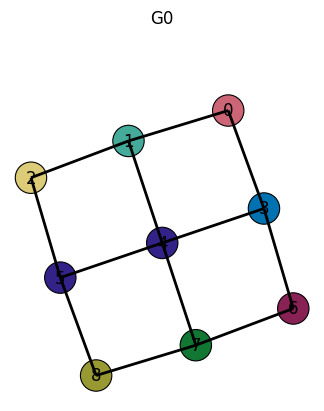

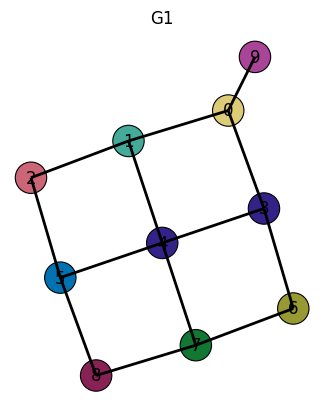

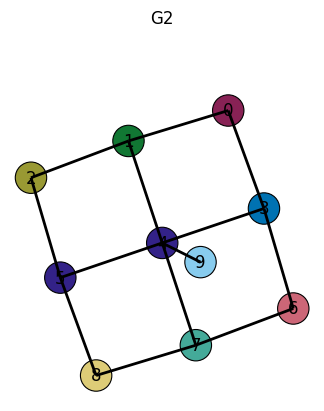

In [15]:
# 5) Color transfer from barycenter to inputs
# Assign a color to each barycenter node; transfer to input graphs via coupling.

import re
from matplotlib.patches import Wedge, Circle

_HEX = re.compile(r"^#[0-9a-fA-F]{6}$")


def draw_nodes_with_pies(G, pos, node_size, ax):
    """
    Draw nodes with optional multi-color pies.
    Colors are taken from node attributes whose keys are hex strings '#RRGGBB'
    and values are nonnegative weights.
    """

    def radius_data_units():
        r_pts = np.sqrt(max(node_size, 1e-9) / np.pi)
        fig = ax.figure
        bbox = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
        ax_w_in, ax_h_in = bbox.width, bbox.height
        (xmin, xmax) = ax.get_xlim()
        (ymin, ymax) = ax.get_ylim()
        dx = max(xmax - xmin, 1e-12)
        dy = max(ymax - ymin, 1e-12)
        r_in = r_pts / 72.0
        r_data_x = r_in * dx / max(ax_w_in, 1e-12)
        r_data_y = r_in * dy / max(ax_h_in, 1e-12)
        return min(r_data_x, r_data_y)

    default_nodes = []
    solid_nodes = []
    pie_nodes = []

    for n in G.nodes():
        attrs = G.nodes[n]
        items = [(k, attrs[k]) for k in attrs if isinstance(k, str) and _HEX.match(k)]
        if not items:
            default_nodes.append(n)
        else:
            parts = [(c, float(abs(w))) for c, w in items if np.isfinite(w)]
            parts = [(c, w) for c, w in parts if w > 0]
            if not parts:
                default_nodes.append(n)
            elif len(parts) == 1:
                solid_nodes.append((n, parts[0][0]))
            else:
                pie_nodes.append((n, parts))

    if default_nodes:
        nx.draw_networkx_nodes(G, pos, nodelist=default_nodes, node_color="#FFFFFF", node_size=node_size, ax=ax)

    by_color = {}
    for n, c in solid_nodes:
        by_color.setdefault(c, []).append(n)
    for c, nodes in by_color.items():
        nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_color=c, node_size=node_size, ax=ax)

    ax.autoscale(enable=False)
    r_data = radius_data_units()
    for n, parts in pie_nodes:
        x, y = pos[n]
        total = sum(w for _, w in parts)
        if total <= 0:
            nx.draw_networkx_nodes(G, pos, nodelist=[n], node_color="#aaaaaa", node_size=node_size, ax=ax)
            continue
        start = 90.0
        for color, w in parts:
            frac = w / total
            theta2 = start - 360.0 * frac
            wedge = Wedge((x, y), r_data, theta2, start, facecolor=color, edgecolor="none")
            ax.add_patch(wedge)
            start = theta2
        ax.add_patch(Circle((x, y), r_data, facecolor="none", edgecolor="black", linewidth=0.8))


def transfer_colors(G_center, G_inputs, Ts, colors, weight_mode="p"):
    """
    Assign each barycenter node a unique color, then transfer to input graphs
    by mixing colors using coupling weights.

    weight_mode:
      - "p": scale barycenter colors by p (if available in log)
      - "uniform": all barycenter nodes equal weight
    """
    for G in [G_center] + G_inputs:
        for n in G.nodes():
            for k in list(G.nodes[n].keys()):
                if isinstance(k, str) and k.startswith("#"):
                    G.nodes[n].pop(k, None)

    if weight_mode == "p" and ("p" in log):
        base_w = log["p"]
        base_w = base_w / max(base_w.max(), 1e-12)
    else:
        base_w = np.ones(G_center.number_of_nodes())

    for i, n in enumerate(G_center.nodes()):
        color = colors[i % len(colors)]
        G_center.nodes[n][color] = float(base_w[i])

    for g_idx, G in enumerate(G_inputs):
        T = Ts[g_idx]
        for j in G.nodes():
            for i in range(T.shape[0]):
                w = T[i, j]
                if w <= 0:
                    continue
                for color in [c for c in G_center.nodes[i] if isinstance(c, str) and c.startswith("#")]:
                    G.nodes[j][color] = G.nodes[j].get(color, 0.0) + G_center.nodes[i][color] * w


# Build barycenter graph and transfer colors
layout_seed = 31  # match Step 2 visualization seed
barycenter_seed = 7  # match Cell (4.2) barycenter layout seed

G_center = _graph_from_adjacency_threshold(C_center, tol=0.0)
Ts = log["T"]

# Color palette (repeat if needed)
colors = [
    "#332288", "#117733", "#44AA99", "#88CCEE", "#DDCC77",
    "#CC6677", "#AA4499", "#882255", "#0072B2", "#999933",
]

transfer_colors(G_center, [Gs[idx] for idx in idx_list], Ts, colors, weight_mode="p")

# Draw barycenter + inputs, but keep G0/G1 layouts as before
# (only colors are transferred; node locations stay from their own layouts)

# Barycenter layout (separate) with edge alpha from relation weights
# Use the same layout method/seed as Cell (4.2)
pos_center = nx.spring_layout(G_center, seed=barycenter_seed)

# bbox to avoid clipping
xs, ys = zip(*pos_center.values()) if pos_center else ([0.0], [0.0])
xs, ys = list(xs), list(ys)
xmin, xmax = min(xs), max(xs)
ymin, ymax = min(ys), max(ys)
wx, wy = xmax - xmin, ymax - ymin
if wx == 0:
    wx = 1e-6
if wy == 0:
    wy = 1e-6
pad = 0.08
xmin -= pad * wx
xmax += pad * wx
ymin -= pad * wy
ymax += pad * wy

fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

draw_nodes_with_pies(G_center, pos_center, node_size=600, ax=ax)

# edge alpha encodes relation weight
ws = [d.get("weight", 0.0) for _, _, d in G_center.edges(data=True)]
if ws:
    wmin, wmax = min(ws), max(ws)
    if wmax <= wmin:
        alphas = [1.0] * len(ws)
    else:
        alphas = [(w - wmin) / (wmax - wmin) for w in ws]
else:
    alphas = []

for (e, a) in zip(G_center.edges(), alphas):
    nx.draw_networkx_edges(G_center, pos_center, edgelist=[e], ax=ax, width=2.0, alpha=a)

nx.draw_networkx_labels(G_center, pos_center, ax=ax)
ax.set_title("Barycenter")
ax.set_axis_off()
plt.show()

# Input layouts: use the same layout/scaling as the original visualization for G0/G1
input_graphs = [Gs[idx] for idx in idx_list]
input_positions = _unified_layout(input_graphs, base_index=0, seed=layout_seed)

# shared bbox for consistent scale across G0/G1
xs, ys = [], []
for pos in input_positions:
    for x, y in pos.values():
        xs.append(x)
        ys.append(y)
if not xs:
    xs, ys = [0.0], [0.0]
xmin, xmax = min(xs), max(xs)
ymin, ymax = min(ys), max(ys)
wx, wy = xmax - xmin, ymax - ymin
if wx == 0:
    wx = 1e-6
if wy == 0:
    wy = 1e-6
pad = 0.08
xmin -= pad * wx
xmax += pad * wx
ymin -= pad * wy
ymax += pad * wy

for title, G, pos in zip([f"G{idx}" for idx in idx_list], input_graphs, input_positions):
    fig, ax = plt.subplots(figsize=(4.8, 4.8))
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    draw_nodes_with_pies(G, pos, node_size=600, ax=ax)
    nx.draw_networkx_edges(G, pos, ax=ax, width=2.0)
    nx.draw_networkx_labels(G, pos, ax=ax)
    ax.set_title(title)
    ax.set_axis_off()
    plt.show()

